# Mouse perimetrium: cell-type annotation (stage 04c)

Every cluster of the re-integrated perimetrium lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_mouse_perimetrium.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/mouse_perimetrium.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "mouse", "perimetrium", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_mouse_perimetrium.h5ad"
TABLE = REPO / "resources/annotations/mouse_perimetrium.csv"
PANEL = ['Sox6', 'Msln', 'Upk3b', 'Wt1', 'Cdh1', 'Pax8', 'Pdgfra', 'Prl8a2', 'Acta2', 'Myh11', 'Flt1', 'Pecam1', 'Ptprc']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,perimetrial_cell,22,leiden_scVI_3.0,"Msln 0.50; Upk3b 0.77; Wt1 0.95 | top vs lineage: Igf1 1.00, Rplp2 0.95, Prlr 0.77"
1,perimetrial_cell,37,leiden_scVI_3.0,"Msln 0.62; Upk3b 0.97; Wt1 0.86 | top vs lineage: Eif1 0.81, Igf1 0.97, Txnip 0.92"
2,perimetrial_cell,14,leiden_scVI_3.0,"Msln 0.50; Upk3b 0.71; Wt1 0.50 | top vs lineage: Mtss1 0.71, Ddx5 0.93, Zfand3 0.93"
3,perimetrial_cell,34,leiden_scVI_3.0,"Msln 0.38; Upk3b 0.82; Wt1 0.71 | top vs lineage: Ltbp4 0.85, Fth1 0.85, Sugct 0.79"
4,perimetrial_cell,48,leiden_scVI_3.0,"Msln 0.35; Upk3b 0.52; Wt1 0.73 | top vs lineage: Nkain2 0.96, Synpr 0.73, Zfpm2 0.98"
5,perimetrial_cell,33,leiden_scVI_3.0,"Msln 0.27; Upk3b 0.73; Wt1 0.82 | top vs lineage: Igf1 1.00, Adgrl3 0.85, Rora 1.00"
6,perimetrial_cell,12,leiden_scVI_3.0,"Msln 0.42; Upk3b 0.83; Wt1 0.92 | top vs lineage: Rbm12b2 0.67, Bnc2 1.00, Dcn 1.00"
7,perimetrial_cell,30,leiden_scVI_3.0,"Msln 0.07; Upk3b 0.67; Wt1 0.73 | top vs lineage: Prkce 0.90, Prkd1 0.70, Kazn 0.87"
8,EXCLUDE,15,leiden_scVI_3.0,"EXCLUDE: conservative exclusion; doublet med 0.72 (lineage q75 0.45), genes med 2143 (lineage q25 1020), co-expression 0.20"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

654 nuclei; 25 clusters
{'perimetrial_cell': 550, 'EXCLUDE': 104}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

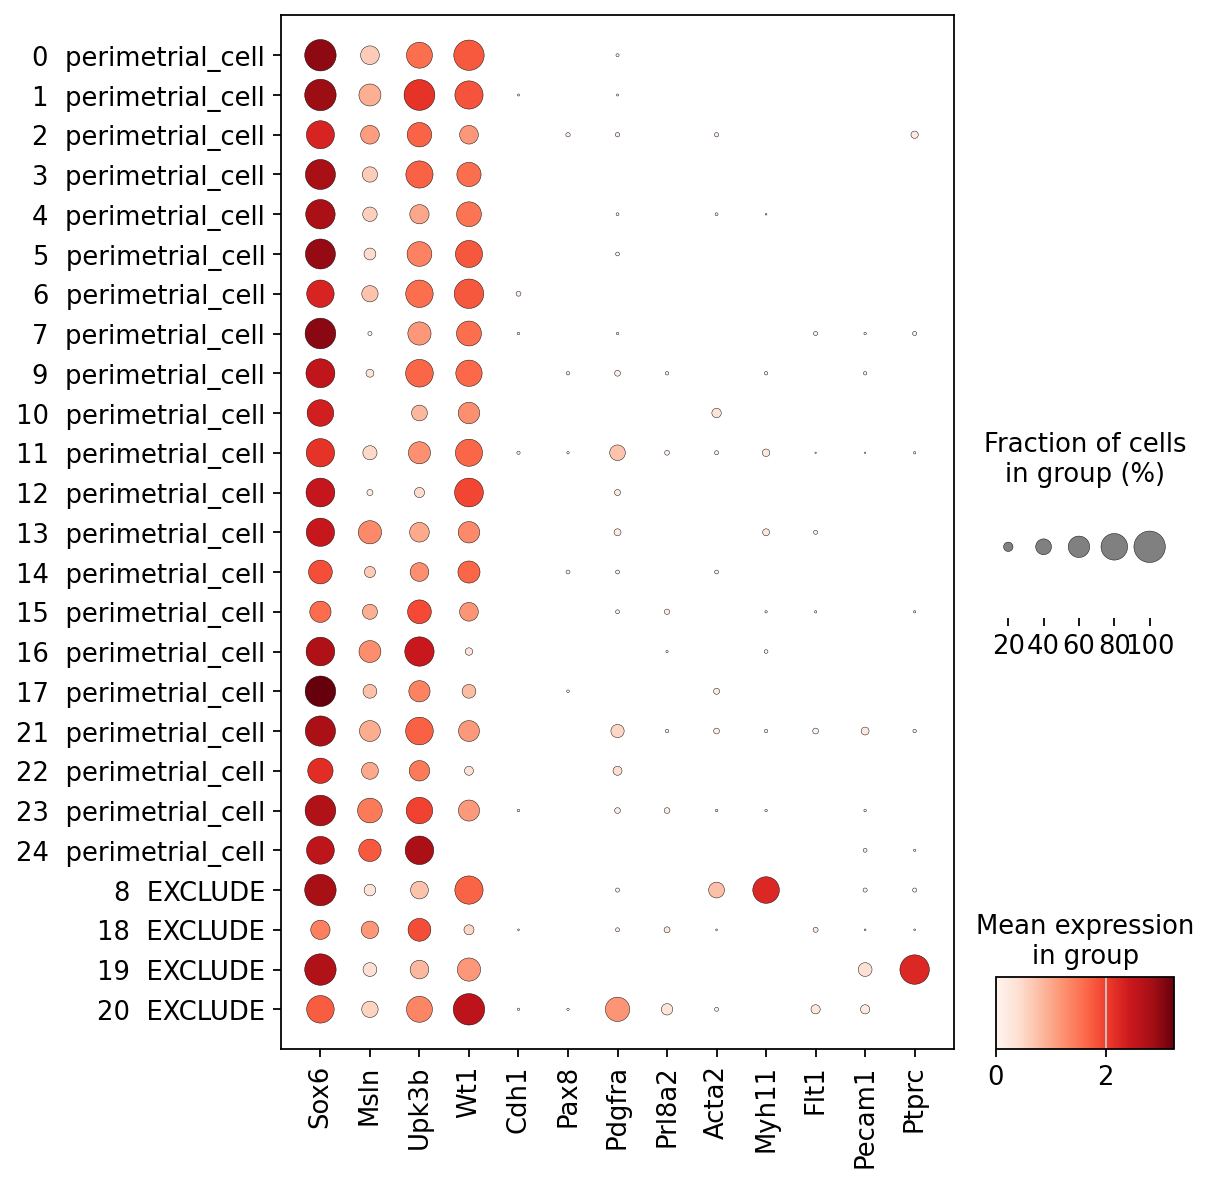

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference. A high doublet score together with markers of another lineage
(section 6) is what an EXCLUDE call rests on; a moderate score alone is not
(cycling clusters score around 1 throughout this dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,22,perimetrial_cell,0.00,2344.5,4253.5
1,37,perimetrial_cell,0.00,2455.0,4728.0
2,14,perimetrial_cell,0.64,932.0,1229.5
3,34,perimetrial_cell,0.00,1829.0,2868.0
4,48,perimetrial_cell,0.05,1768.5,2899.0
5,33,perimetrial_cell,0.00,1984.0,3298.0
6,12,perimetrial_cell,0.05,1791.0,2758.0
7,30,perimetrial_cell,0.40,1943.5,3127.5
9,19,perimetrial_cell,0.00,2089.0,3473.0


## 5. UMAP by cluster and by label

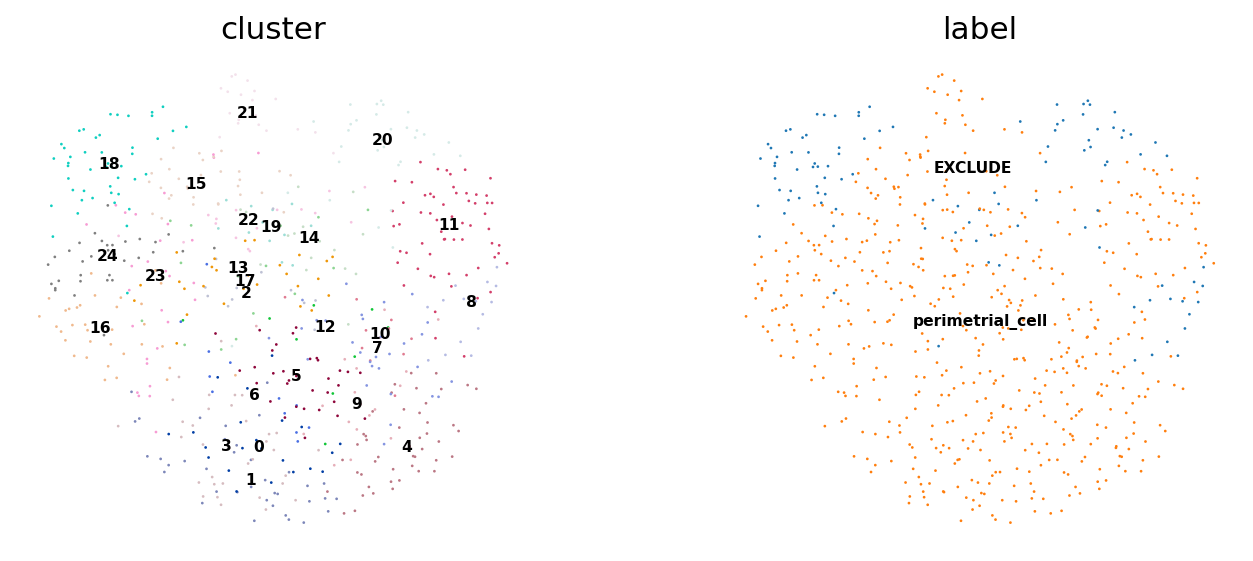

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

,Sox6,Msln,Upk3b,Wt1,Cdh1,Pax8,Pdgfra,Prl8a2,Acta2,Myh11,Flt1,Pecam1,Ptprc
8,1.00,0.27,0.47,0.87,0.00,0.00,0.07,0.00,0.40,0.80,0.00,0.07,0.07
18,0.52,0.46,0.65,0.22,0.02,0.00,0.07,0.11,0.02,0.00,0.09,0.02,0.02
19,1.00,0.33,0.50,0.67,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.33,0.92
20,0.84,0.42,0.77,1.00,0.03,0.03,0.71,0.26,0.06,0.00,0.19,0.19,0.00
lineage,0.86,0.41,0.70,0.61,0.01,0.01,0.12,0.04,0.04,0.05,0.03,0.03,0.03
